In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

from pyoptics.coatings import Coating
from pyoptics.materials import Isotropic, extinction_from_absorption
from pyoptics.raytrace import caldwell_krf_lens, fused_silica
from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, lens

plt.rcParams.update({"figure.dpi": 80, "font.size": 11})
t_start = time.time()

system = caldwell_krf_lens()           # lengths in mm
WL = system.wavelength_nm              # simulation length unit: nm
NA = lens.lens_NA(system)
m = system.paraxial().magnification
n_glass = fused_silica(WL)
R_FIELD = 11.7                         # image field radius (mm)
SLIT_X, SLIT_Y = 10.5, 2.5             # half widths of a 21 x 5 mm slit
print(f"wavelength {WL:.1f} nm, NA {NA:.4f}, magnification {m:.4f}, fused silica n = {n_glass:.4f}")

wavelength 248.3 nm, NA 0.5581, magnification -0.2500, fused silica n = 1.5084


## 1. Lens, coatings and slit

The lens has 21 fused silica elements, 42 glass–air surfaces. Uncoated,
each reflects 4 % at normal incidence and the lens transmits only 17 %;
every surface needs an antireflection coating. Four variants, all thin
films on every surface (`coating=` of `lens_telecentricity()`, from the air
side), designed for normal incidence:

| coating | layers | R at 0° |
|---|---|---|
| uncoated | – | 4.1 % |
| ideal single layer | $\lambda/4$ of $n = \sqrt{n_\mathrm{glass}} = 1.228$ (no such material exists) | 0 |
| MgF$_2$ single layer | $\lambda/4$ of $n = 1.415$, the lowest index available in the DUV | 1.6 % |
| LaF$_3$/MgF$_2$ V coat | $\lambda/4$ MgF$_2$ on $\lambda/4$ LaF$_3$ ($n = 1.69$) | 0.1 % |

Fused silica for KrF absorbs a little; we take an internal transmission of
99.8 % per cm ($\alpha = 0.002$/cm), as an absorbing medium
(`materials.Isotropic(n, k)`) behind every glass surface. The **coated lens**
of the later sections is the V coat with this absorption.

21 elements, 565 mm of glass on axis: internal transmission 0.893


largest angles of incidence on the surfaces (deg): [82.9 65.5 51.7 51.5 50.5 50.  47.5 45.8]


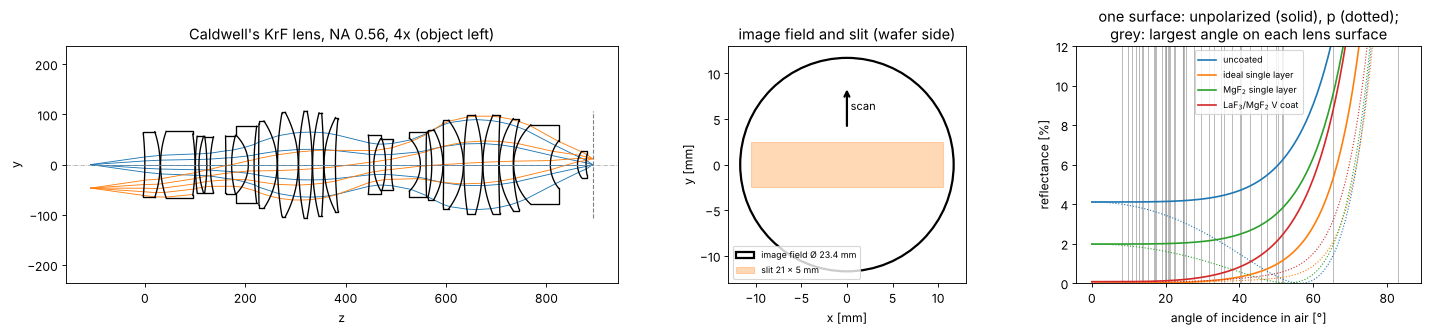

In [2]:
wl = system.wavelength                 # mm
N_MGF2, N_LAF3 = 1.415, 1.69
coatings = {"uncoated": None,
            "ideal single layer": lens.quarter_wave_coating(n_glass, wl),
            "MgF$_2$ single layer": [(N_MGF2, wl/(4*N_MGF2))],
            "LaF$_3$/MgF$_2$ V coat": [(N_MGF2, wl/(4*N_MGF2)), (N_LAF3, wl/(4*N_LAF3))]}
V_COAT = coatings["LaF$_3$/MgF$_2$ V coat"]

ALPHA = 0.002/10                        # 1/mm
k_glass = extinction_from_absorption(ALPHA, wl)
glass = [i for i in range(len(system.surfaces)) if system.n[i + 1] > 1.2]
absorbing = {i: Isotropic(n_glass, k_glass) for i in glass}
path = sum(s.thickness for i, s in enumerate(system.surfaces) if i in glass)
print(f"{len(glass)} elements, {path:.0f} mm of glass on axis: internal transmission "
      f"{np.exp(-ALPHA*path):.3f}")


def max_angles_in_air(system, fields, N=21):
    """Largest angle of incidence (in air) on each surface over the pupil and the fields."""
    n = system.n
    frames = system.frames()[0]
    p = np.linspace(-1, 1, N)
    PX, PY = np.meshgrid(p, p)
    inside = PX**2 + PY**2 <= 1
    worst = np.zeros(len(system.surfaces))
    for f in fields:
        b = system.trace_pupil((0.0, f/m), PX[inside], PY[inside])
        for i, s in enumerate(system.surfaces):
            o, R = frames[i]
            Q = (b.points[i + 1][b.valid] - o) @ R
            cos_i = np.abs(np.sum(s.normal(Q)*(b.directions[i][b.valid] @ R), axis=-1))
            worst[i] = max(worst[i], np.max(max(n[i], n[i + 1])*np.sqrt(1 - cos_i**2)))
    return np.degrees(np.arcsin(np.clip(worst, 0, 1)))


aoi = max_angles_in_air(system, (0.0, R_FIELD))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3), gridspec_kw={"width_ratios": [1.6, 1, 1]})
system.draw(ax=axes[0], fields=[(0.0, 0.0), (0.0, R_FIELD/m)], n_rays=5)
axes[0].set_title("Caldwell's KrF lens, NA 0.56, 4x (object left)")
ax = axes[1]
ax.add_patch(Circle((0, 0), R_FIELD, fill=False, lw=2, label="image field Ø 23.4 mm"))
ax.add_patch(Rectangle((-SLIT_X, -SLIT_Y), 2*SLIT_X, 2*SLIT_Y, alpha=0.3, color="C1",
                       label="slit 21 × 5 mm"))
ax.annotate("", xy=(0, 8.5), xytext=(0, 4), arrowprops=dict(arrowstyle="->", lw=2))
ax.text(0.4, 6, "scan", fontsize=10)
ax.set_aspect("equal"); ax.set_xlim(-13, 13); ax.set_ylim(-13, 13)
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("image field and slit (wafer side)")
ax = axes[2]
angles = np.radians(np.linspace(0, 85, 171))
for k, (name, layers) in enumerate(coatings.items()):
    out = Coating(layers or []).power(angles, 1.0, n_glass, wl)
    ax.plot(np.degrees(angles), 100*(out["R_s"] + out["R_p"])/2, color=f"C{k}", label=name)
    ax.plot(np.degrees(angles), 100*out["R_p"], ":", color=f"C{k}", lw=1)
for a in aoi:
    ax.axvline(a, color="0.6", lw=0.6, zorder=0)
ax.set_xlabel("angle of incidence in air [°]"); ax.set_ylabel("reflectance [%]")
ax.set_ylim(0, 12); ax.legend(fontsize=8)
ax.set_title("one surface: unpolarized (solid), p (dotted);\ngrey: largest angle on each lens surface")
fig.tight_layout()
print("largest angles of incidence on the surfaces (deg):", np.round(np.sort(aoi)[::-1][:8], 1))

The single layer coatings and the V coat work at normal incidence, but
many surfaces see angles of 30–50° and a few, steep surfaces at the rim
of the field even 65–83° (grey lines), where the reflectance rises
quickly and differs for s and p. Off axis, the rays above and below
the chief ray meet these surfaces at different angles: this is where the
asymmetric apodization comes from.

The slit: 21 × 5 mm fits into the 23.4 mm image field of this stepper
lens (a scanner lens of 4x has a 26 × 8 mm slit, but the principle is the
same). Mask and wafer move along $y$; every wafer point sees all $y$ of the
slit at its slit position $x$.

## 2. Chief ray telecentricity

Caldwell's paper calls the lens telecentric on both sides; the chief rays
of the model (stop on surface 30, see `caldwell_krf_lens()`) leave it
within a few mrad of the axis. The lens is rotationally symmetric, so the
chief ray tilt is radial and a function of the field radius $r$ only.

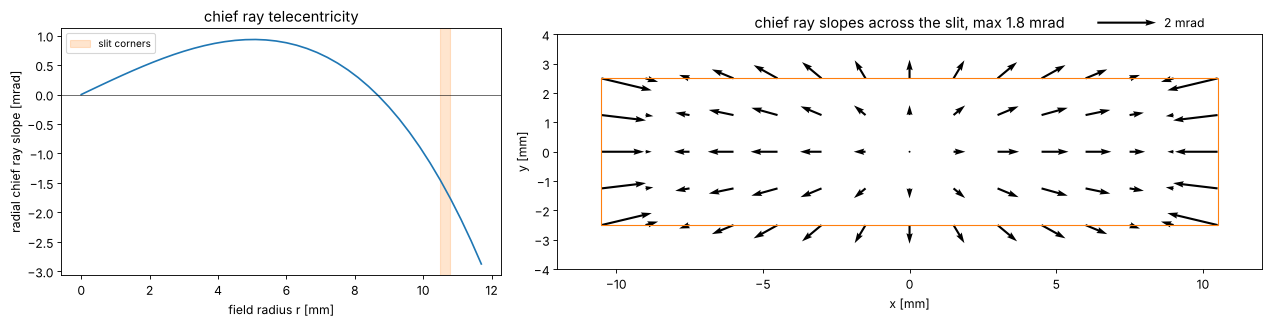

In [3]:
def chief_slope(field):
    """Image space chief ray slope (dx/dz, dy/dz) at an image field point."""
    b = system.trace_pupil(np.asarray(field, dtype=float)/m, 0.0, 0.0)
    d = system._image_hits(b)[1][0]
    return d[:2]/d[2]


r = np.linspace(0, R_FIELD, 40)
chief_r = np.array([chief_slope((x, 0.0))[0] for x in r])*1e3
xs = np.linspace(-SLIT_X, SLIT_X, 15)
ys = np.linspace(-SLIT_Y, SLIT_Y, 5)
F = np.array([(x, y) for y in ys for x in xs])
C = np.array([chief_slope(f) for f in F])*1e3

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].plot(r, chief_r, "C0-")
axes[0].axvspan(SLIT_X, np.hypot(SLIT_X, SLIT_Y), color="C1", alpha=0.2, label="slit corners")
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_xlabel("field radius r [mm]"); axes[0].set_ylabel("radial chief ray slope [mrad]")
axes[0].set_title("chief ray telecentricity"); axes[0].legend(fontsize=9)
q = axes[1].quiver(F[:, 0], F[:, 1], C[:, 0], C[:, 1], angles="xy", scale_units="xy", scale=1,
                   width=0.003)
axes[1].quiverkey(q, 0.85, 1.05, 2, "2 mrad", labelpos="E")
axes[1].add_patch(Rectangle((-SLIT_X, -SLIT_Y), 2*SLIT_X, 2*SLIT_Y, fill=False, color="C1"))
axes[1].set_aspect("equal"); axes[1].set_xlim(-12, 12); axes[1].set_ylim(-4, 4)
axes[1].set_xlabel("x [mm]"); axes[1].set_ylabel("y [mm]")
axes[1].set_title(f"chief ray slopes across the slit, max {np.max(np.hypot(*C.T)):.1f} mrad")
fig.tight_layout()

The chief ray tilt stays below about 2 mrad in the slit; it changes sign
at about 9 mm (the design balances it over the field). By the chief ray
alone this is a good telecentric lens: 100 nm of defocus move the image by
at most 0.2 nm.

## 3. The cone of light

The chief ray is the centre of the stop; the light is the whole cone that
passes the stop and, before that, what the illuminator puts into it.
`lens_telecentricity()` traces a grid of rays through the stop from the
object point and weights each ray with its **etendue**, the object side
solid angle of its tube $\mathrm{d}u_x\,\mathrm{d}u_y$ of direction sines
(from the Jacobian of the ray aiming), and with the **illumination fill**:
a uniform source of radius $\sigma$ (in units of the object side NA,
centred on the object side chief ray), or `fill=None` for the whole cone
that the stop passes (the light diffracted by a small feature, or
incoherent light). Its `geometric` result is the centroid of the image
side slopes without losses, `energetic` the same with the transmission of
each ray.

First the pupil itself at the slit edge, $x = 10.5$ mm: the image side
directions of the rays relative to the chief ray, in units of the NA, and
the etendue weight of each ray.

x = 10.5 mm: the cone reaches from P_x = -1.013 to 0.902, centre -0.056 (in NA units)


sigma 0.2: centroid -1.48 mrad
sigma 0.5: centroid -1.67 mrad
sigma 0.8: centroid -1.49 mrad
whole cone: -36.13 mrad, chief ray -1.45 mrad


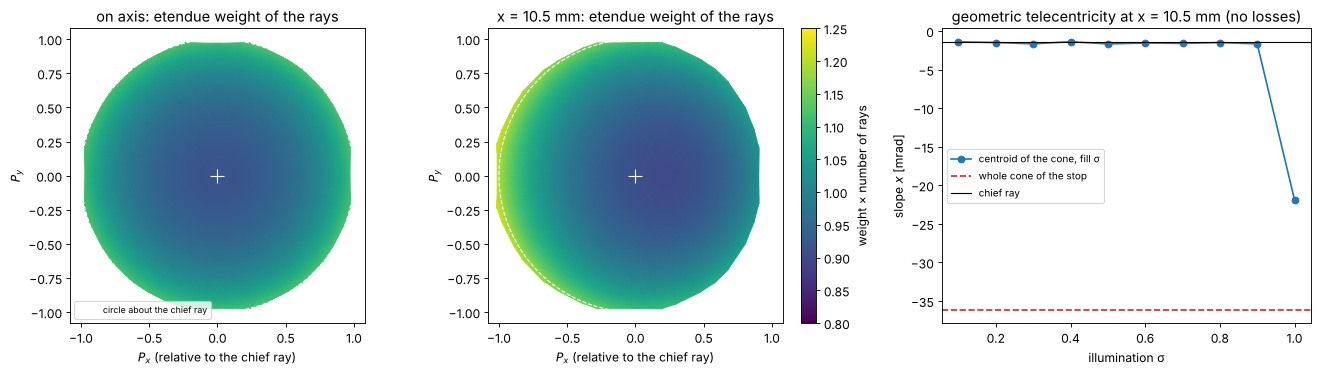

In [4]:
X_EDGE = SLIT_X
full_edge = lens.lens_telecentricity(system, (X_EDGE, 0.0), N=64)
axis = lens.lens_telecentricity(system, (0.0, 0.0), N=64)
phi = np.linspace(0, 2*np.pi, 361)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, t, title in ((axes[0], axis, "on axis"), (axes[1], full_edge, f"x = {X_EDGE} mm")):
    im = ax.tripcolor(t.P_x, t.P_y, t.weight*len(t.weight), shading="gouraud", cmap="viridis",
                      vmin=0.8, vmax=1.25)
    ax.plot(np.cos(phi), np.sin(phi), "w--", lw=1, label="circle about the chief ray")
    ax.plot(0, 0, "w+", ms=12)
    ax.set_aspect("equal"); ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08)
    ax.set_xlabel("$P_x$ (relative to the chief ray)"); ax.set_ylabel("$P_y$")
    ax.set_title(f"{title}: etendue weight of the rays")
plt.colorbar(im, ax=axes[1], label="weight × number of rays")
axes[0].legend(fontsize=8, loc="lower left")
x_rim = [full_edge.P_x.min(), full_edge.P_x.max()]
print(f"x = {X_EDGE} mm: the cone reaches from P_x = {x_rim[0]:.3f} to {x_rim[1]:.3f}, "
      f"centre {np.mean(x_rim):+.3f} (in NA units)")

# the centroid against the illumination fill
sigmas = np.linspace(0.1, 1.0, 10)
cases = [(s, lens.lens_telecentricity(system, (X_EDGE, 0.0), N=64, fill=s)) for s in sigmas]
ax = axes[2]
ax.plot(sigmas, [1e3*t.geometric[0] for _, t in cases], "o-", label="centroid of the cone, fill σ")
ax.axhline(1e3*full_edge.geometric[0], color="C3", ls="--", label="whole cone of the stop")
ax.axhline(1e3*full_edge.chief[0], color="k", lw=1, label="chief ray")
ax.set_xlabel("illumination σ"); ax.set_ylabel("slope $x$ [mrad]")
ax.set_title(f"geometric telecentricity at x = {X_EDGE} mm (no losses)"); ax.legend(fontsize=9)
fig.tight_layout()
for s, t in cases[1::3]:
    print(f"sigma {s:.1f}: centroid {1e3*t.geometric[0]:+.2f} mrad")
print(f"whole cone: {1e3*full_edge.geometric[0]:+.2f} mrad, chief ray {1e3*full_edge.chief[0]:+.2f} mrad")

Two findings:

- **The pupil is decentred.** On axis the cone is a disk about the chief
  ray. At the slit edge it is shifted by about 5 % of its radius to $-x$
  (its rim reaches $P_x \approx -1.01$ on one side and $+0.90$ on the other):
  the chief ray goes through the centre of the stop, but seen from the
  off-axis object point the stop is not centred on it (pupil coma of the
  front group). The whole cone of the stop is therefore tilted by
  about −36 mrad, 25 times the chief ray. This depends on where the
  stop is, which Caldwell's paper does not say: with a stop on the almost
  flat surface 31 instead of the strongly curved surface 30 (whose rim
  lies 18 mm in front of its vertex) the chief rays are as telecentric,
  and the decentration is about 2.5 times smaller (at a somewhat smaller
  NA).
- **A symmetric illumination is not affected.** A source of $\sigma \le
  0.9$ centred on the object side chief ray stays inside the stop, and its
  cone is centred on the chief ray in image space too, to a few tenths of a
  mrad: the
  lens maps object side directions to image side directions linearly
  (with the factor 1/m, the sine condition), so a disk stays a disk about
  the chief ray. At σ = 1 the disk touches the decentred stop on one side
  and the centroid jumps.

So the light of the illuminator (the zero order of a mask) arrives
telecentric, while light diffracted to the rim of the pupil (small
features) sees the decentred stop. Without losses, this is all of the
geometry; now the transmission.

## 4. Apodization and energetic telecentricity

The polarization ray trace gives the power transmission of every ray for
unpolarized light: Fresnel coefficients or the thin film stack on every
surface, and the absorption on the path through the glass. Relative to
the chief ray, at the slit edge:

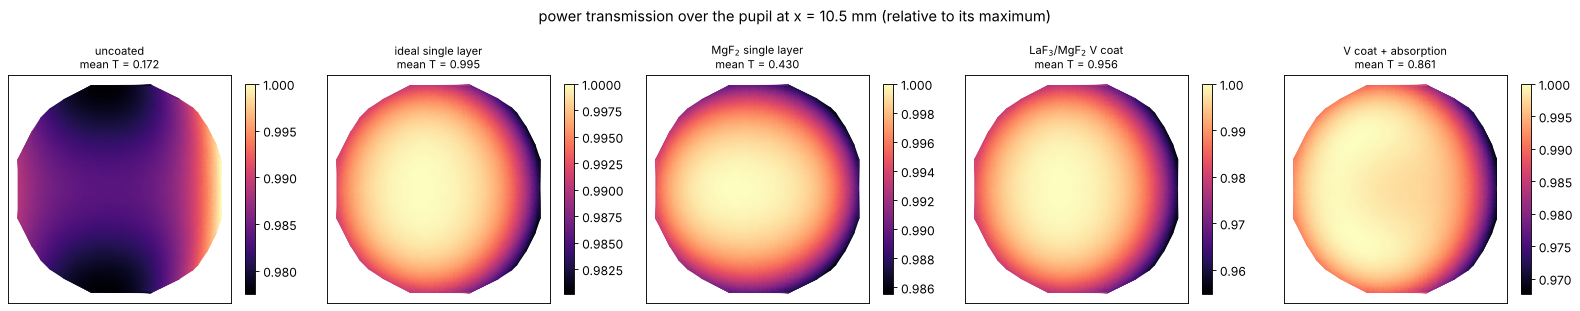

In [5]:
variants = dict(coatings)
variants["V coat + absorption"] = V_COAT


def trace(field, name, N=48, fill=None):
    c = variants[name]
    media = absorbing if name == "V coat + absorption" else None
    return lens.lens_telecentricity(system, field, N=N, fill=fill, coating=c, birefringent=media)


edge = {name: trace((X_EDGE, 0.0), name) for name in variants}
fig, axes = plt.subplots(1, 5, figsize=(20, 4.0))
for ax, (name, t) in zip(axes, edge.items()):
    rel = t.T/np.max(t.T)
    im = ax.tripcolor(t.P_x, t.P_y, rel, shading="gouraud", cmap="magma")
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nmean T = {t.transmission:.3f}", fontsize=10)
    plt.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f"power transmission over the pupil at x = {X_EDGE} mm (relative to its maximum)", y=1.02)
fig.tight_layout()

- **Uncoated**, the transmission *rises* towards the rim in $x$, most on
  the $+x$ side, where the rays meet the surfaces closer to Brewster's
  angle ($p$ is transmitted better; the radial diattenuation of notebook
  38), and falls towards $\pm y$.
- The **coatings** have the opposite trend: designed for normal incidence,
  they reflect more at large angles, so the transmission falls towards the
  rim of the pupil, by 1–2 % for the single layers and 4 % for the V coat,
  whose reflectance rises fastest with the angle (section 1), and more on
  the $+x$ side.
- The **absorption** takes 11 % on axis and varies with the glass path
  across the pupil; it partly fills in the rim on the $-x$ side.

Off axis, none of these patterns is symmetric about the chief ray. Its
tilt part moves the energy centroid. The energetic telecentricity, the
centroid weighted with this transmission, against the geometric centroid,
for the whole cone and for a conventional illumination of $\sigma = 0.8$:

uncoated                   x = 10.5 mm, sigma 0.8: chief -1.45, geometric -1.49, energetic -1.04 mrad
ideal single layer         x = 10.5 mm, sigma 0.8: chief -1.45, geometric -1.49, energetic -1.92 mrad
MgF$_2$ single layer       x = 10.5 mm, sigma 0.8: chief -1.45, geometric -1.49, energetic -1.74 mrad
LaF$_3$/MgF$_2$ V coat     x = 10.5 mm, sigma 0.8: chief -1.45, geometric -1.49, energetic -2.51 mrad
V coat + absorption        x = 10.5 mm, sigma 0.8: chief -1.45, geometric -1.49, energetic -2.27 mrad


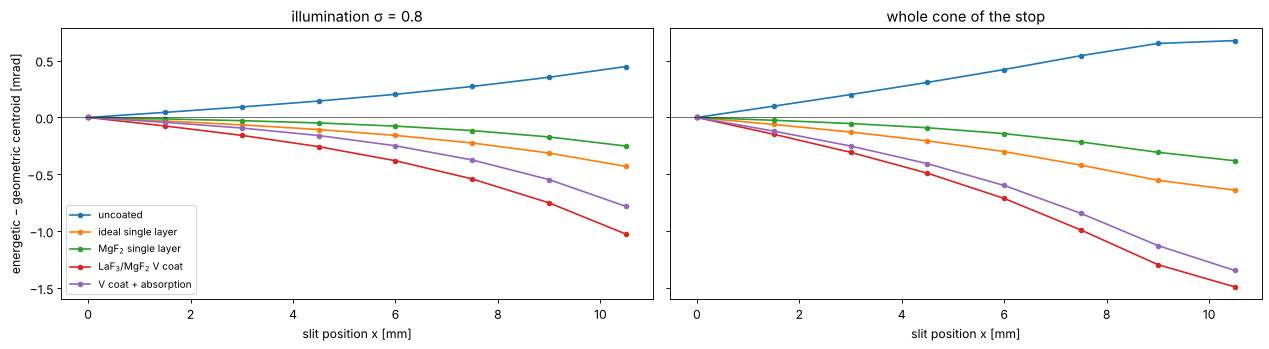

In [6]:
xs_half = np.linspace(0, SLIT_X, 8)
SIGMA = 0.8
rows = {}
for name in variants:
    for fill in (None, SIGMA):
        rows[name, fill] = [trace((x, 0.0), name, N=48, fill=fill) for x in xs_half]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, fill, title in ((axes[0], SIGMA, f"illumination σ = {SIGMA}"),
                        (axes[1], None, "whole cone of the stop")):
    for k, name in enumerate(variants):
        d = [1e3*(t.energetic[0] - t.geometric[0]) for t in rows[name, fill]]
        ax.plot(xs_half, d, "o-", color=f"C{k}", ms=4, label=name)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("slit position x [mm]"); ax.set_title(title)
axes[0].set_ylabel("energetic − geometric centroid [mrad]")
axes[0].legend(fontsize=9)
fig.tight_layout()
for name in variants:
    t = rows[name, SIGMA][-1]
    print(f"{name:26s} x = {SLIT_X} mm, sigma {SIGMA}: chief {1e3*t.chief[0]:+.2f}, geometric "
          f"{1e3*t.geometric[0]:+.2f}, energetic {1e3*t.energetic[0]:+.2f} mrad")

The apodization moves the centroid by up to 1 mrad for the illumination
and 1.5 mrad for the whole cone at the slit edge, the same order as the
chief ray telecentricity itself (−1.5 mrad there), and with a sign that
depends on the coating: the bare lens tilts the light outwards (+x,
towards the transmission rise near Brewster's angle), every coating tilts
it inwards, the V coat most, the MgF$_2$ single layer least. The
absorption works against the V coat a little. The whole cone feels more,
since the rim of the pupil carries the strongest apodization.

A lens that is telecentric by its chief ray can thus be off by a few mrad
energetically, and the coating design is part of the telecentricity
budget. From here on the lens is the **coated lens** (V coat with
absorption).

## 5. Across the slit, static and scanned

Over the whole slit, for three fills: conventional σ = 0.8, annular 0.8/0.5
and the whole cone. The lens is rotationally symmetric, so the slopes are
radial: the $x$ component is odd in $x$, the $y$ component odd in $y$.

conventional σ 0.8: scanned minus static x slope, largest 0.14 mrad
annular 0.8/0.5: scanned minus static x slope, largest 0.17 mrad
conventional σ 0.8  : energetic x slope at the slit edge -2.27 mrad (chief ray -1.45), largest |energetic - chief| in the slit 0.94 mrad
annular 0.8/0.5     : energetic x slope at the slit edge -2.48 mrad (chief ray -1.45), largest |energetic - chief| in the slit 1.23 mrad
whole cone          : energetic x slope at the slit edge -38.01 mrad (chief ray -1.45), largest |energetic - chief| in the slit 37.44 mrad


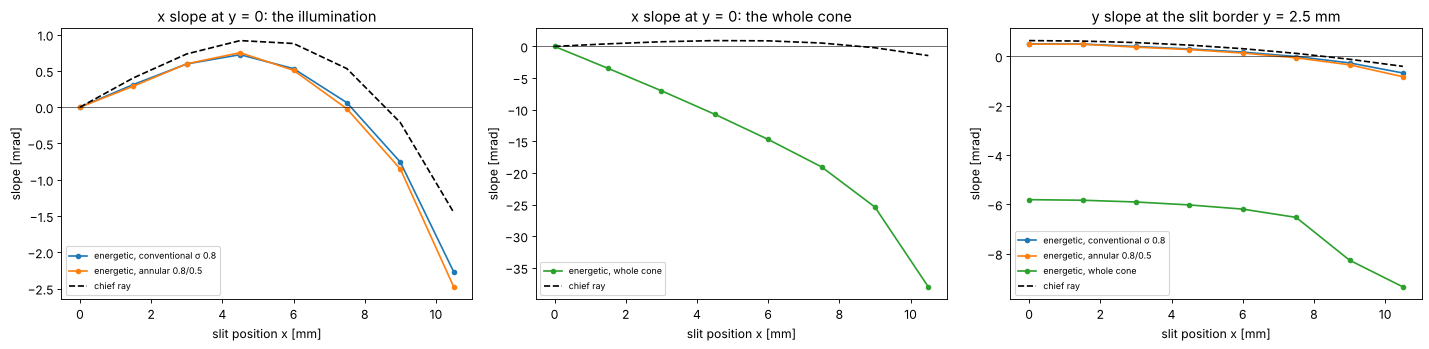

In [7]:
def annular(u_x, u_y, outer=0.8, inner=0.5, h=2/47):
    """Annular fill, edges smoothed over one step of the 48 x 48 pupil grid (as for a number sigma)."""
    rho = np.hypot(u_x, u_y)
    return np.clip((outer - rho)/h + 0.5, 0, 1)*np.clip((rho - inner)/h + 0.5, 0, 1)


fills = {"conventional σ 0.8": 0.8, "annular 0.8/0.5": annular, "whole cone": None}
ys_half = np.linspace(0, SLIT_Y, 3)
slit = {name: [[trace((x, y), "V coat + absorption", N=48, fill=f) for x in xs_half] for y in ys_half]
        for name, f in fills.items()}


def component(results, key, i):
    return np.array([[1e3*getattr(t, key)[i] for t in row] for row in results])


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
chief_x = component(slit["whole cone"], "chief", 0)[0]
for k, (name, res) in enumerate(slit.items()):
    ax = axes[1] if name == "whole cone" else axes[0]
    ax.plot(xs_half, component(res, "energetic", 0)[0], "o-", color=f"C{k}", ms=4, label=f"energetic, {name}")
    ey = component(res, "energetic", 1)
    axes[2].plot(xs_half, ey[-1], "o-", color=f"C{k}", ms=4, label=f"energetic, {name}")
for ax in axes[:2]:
    ax.plot(xs_half, chief_x, "k--", label="chief ray")
axes[2].plot(xs_half, component(slit["whole cone"], "chief", 1)[-1], "k--", label="chief ray")
axes[0].set_title("x slope at y = 0: the illumination")
axes[1].set_title("x slope at y = 0: the whole cone")
axes[2].set_title(f"y slope at the slit border y = {SLIT_Y} mm")
for ax in axes:
    ax.set_xlabel("slit position x [mm]"); ax.set_ylabel("slope [mrad]"); ax.axhline(0, color="k", lw=0.5)
    ax.legend(fontsize=8)
fig.tight_layout()
for name, res in list(slit.items())[:2]:
    ex = component(res, "energetic", 0)
    scanned = np.average(ex, axis=0, weights=[1, 2, 1])   # y = 0, +-1.25, +-2.5 mm (trapezoid rule)
    print(f"{name}: scanned minus static x slope, largest {np.max(np.abs(scanned - ex[0])):.2f} mrad")
for name, res in slit.items():
    ex, cx = component(res, "energetic", 0), component(res, "chief", 0)
    print(f"{name:20s}: energetic x slope at the slit edge {ex[0, -1]:+.2f} mrad "
          f"(chief ray {cx[0, -1]:+.2f}), largest |energetic - chief| in the slit "
          f"{np.max(np.abs(ex - cx)):.2f} mrad")

- For the **illumination** the energetic telecentricity follows the chief
  ray, with an offset of up to about 1 mrad (conventional) to 2 mrad
  (annular, whose light sits at the larger angles where the coatings
  apodize most) from the apodization, largest at the slit edge.
- The **whole cone** is dominated by the decentred stop: up to −38 mrad.
- **Scanning** averages over $y$. The $x$ slope barely changes with $y$
  (the slit is short in $y$), so the scanned value is close to the static
  one at $y = 0$ (printed above). The $y$ slope is odd in $y$: it
  averages to zero, but at the slit border it is about ±0.6 mrad for the
  illumination and up to ±9 mrad for the whole cone. A wafer
  point that is out of focus by $z$ receives images moved by $z\,\theta_y(y)$
  during the scan: the image of horizontal lines is blurred by
  $z\,\Delta\theta_y$ instead of moved (image fading), about 0.1 nm at
  $z$ = 100 nm for the illumination, up to 2 nm for light at the rim of the
  pupil.

## 6. Impact: pattern shift through focus

The lithography simulation describes the lens by its pupil on coordinates
about the chief ray. `lens_apodization()` gives that pupil from the ray
trace: zero outside the real (decentred) pupil and the square root of the
relative transmission inside, for `Projector(apodization=...)`. The
projector gets an NA 6 % larger than the lens so that its disk contains
the shifted pupil; the illumination σ is scaled accordingly. The chief ray
tilt is not in the pupil (its coordinates are relative to the chief ray)
and is added as $z\tan\theta_\mathrm{chief}$, as in `through_slit()` of
notebook 33.

Four patterns, binary mask, conventional illumination σ = 0.8, at the
slit edge, first without the lens aberrations (the pupil and the
apodization only), placement of the feature centre through ±300 nm of
focus:

- a large 2 µm line (an alignment or overlay mark),
- an isolated 200 nm line,
- dense 250 nm lines at a pitch of 500 nm and semi-dense ones at 800 nm.

Each pattern twice: with the real pupil only (decentred, transmission 1)
and with the coated lens (decentred pupil and the transmission).

on axis: {'mark 2 µm': np.float64(0.0), 'iso 200 nm': np.float64(0.0), 'dense 250/500': np.float64(0.0), 'semi-dense 250/800': np.float64(0.0)}
mark 2 µm           : real pupil only  -21.47, coated  -22.03 mrad
iso 200 nm          : real pupil only  -20.78, coated  -21.18 mrad
dense 250/500       : real pupil only  -35.61, coated  -35.92 mrad
semi-dense 250/800  : real pupil only  -22.27, coated  -22.71 mrad
chief ray -1.45, energetic: illumination -2.27, whole cone -38.01; coating part (illumination) -0.78 mrad


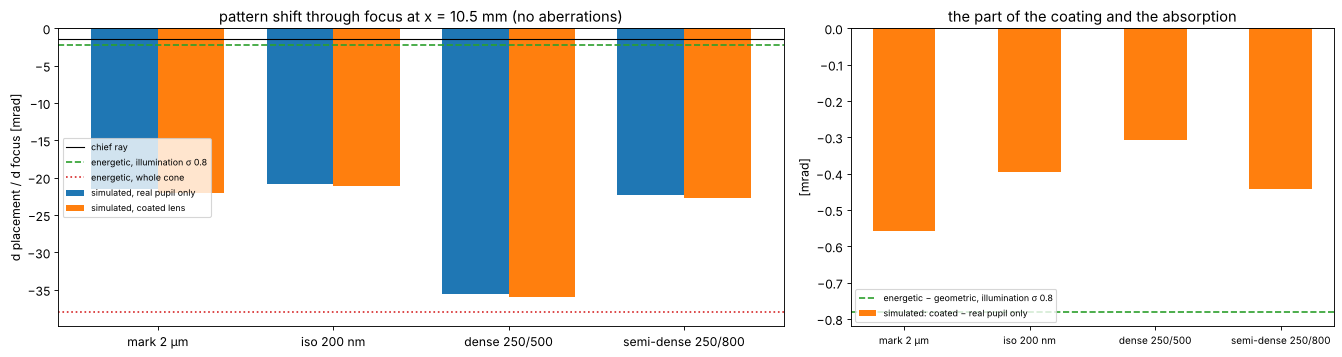

In [8]:
K = 1.06
NA_P = K*NA
FOCI = np.linspace(-300, 300, 7)
patterns = {"mark 2 µm": MaskLayout.iso_line(2000.0, 8000.0),
            "iso 200 nm": MaskLayout.iso_line(200.0, 3000.0),
            "dense 250/500": MaskLayout.lines_spaces(500.0, 250.0),
            "semi-dense 250/800": MaskLayout.lines_spaces(800.0, 250.0)}
ill = Illumination.conventional(SIGMA/K, n_samples=21)


def apodized_projector(field, transmission=True, aberrations=False):
    apo = lens.lens_apodization(system, field, N=48, NA=NA_P, coating=V_COAT, birefringent=absorbing,
                                transmission=transmission)
    z = lens.lens_aberrations(system, field, NA=NA_P, N=40).zernikes if aberrations else None
    return Projector(NA_P, WL, magnification=4.0, apodization=apo, zernikes=z)


def placement_through_focus(layout, projector, field, illumination=ill):
    sim = LithoSimulation(layout, ThinMask.binary(), illumination, projector)
    r = lens.feature_response(sim, threshold=0.3, foci=FOCI)
    return r.placement_focus + FOCI*chief_slope(field)[0]   # plus the chief ray tilt


def slope_of(placement):
    return 1e3*np.polyfit(FOCI, placement, 1)[0]            # mrad


field = (X_EDGE, 0.0)
projectors = {"real pupil only": apodized_projector(field, transmission=False),
              "coated lens": apodized_projector(field)}
slopes = {(name, mode): slope_of(placement_through_focus(layout, P, field))
          for name, layout in patterns.items() for mode, P in projectors.items()}
on_axis = apodized_projector((0.0, 0.0))
print("on axis:", {name: round(slope_of(placement_through_focus(layout, on_axis, (0.0, 0.0))), 4)
                   for name, layout in patterns.items()})
t_ill = slit["conventional σ 0.8"][0][-1]
t_full = slit["whole cone"][0][-1]
coating_part = 1e3*(t_ill.energetic[0] - t_ill.geometric[0])

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
idx = np.arange(len(patterns))
ax = axes[0]
for k, mode in enumerate(projectors):
    ax.bar(idx + (k - 0.5)*0.38, [slopes[n, mode] for n in patterns], 0.38, label=f"simulated, {mode}")
ax.axhline(1e3*t_ill.chief[0], color="k", lw=1, label="chief ray")
ax.axhline(1e3*t_ill.energetic[0], color="C2", ls="--", label=f"energetic, illumination σ {SIGMA}")
ax.axhline(1e3*t_full.energetic[0], color="C3", ls=":", label="energetic, whole cone")
ax.set_xticks(idx); ax.set_xticklabels(patterns); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("d placement / d focus [mrad]"); ax.legend(fontsize=8, loc="center left")
ax.set_title(f"pattern shift through focus at x = {X_EDGE} mm (no aberrations)")
ax = axes[1]
ax.bar(idx, [slopes[n, "coated lens"] - slopes[n, "real pupil only"] for n in patterns], 0.5,
       color="C1", label="simulated: coated − real pupil only")
ax.axhline(coating_part, color="C2", ls="--",
           label=f"energetic − geometric, illumination σ {SIGMA}")
ax.set_xticks(idx); ax.set_xticklabels(patterns, fontsize=9); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("[mrad]"); ax.set_title("the part of the coating and the absorption")
ax.legend(fontsize=8)
fig.tight_layout()
for name in patterns:
    print(f"{name:20s}: real pupil only {slopes[name, 'real pupil only']:+7.2f}, coated "
          f"{slopes[name, 'coated lens']:+7.2f} mrad")
print(f"chief ray {1e3*t_ill.chief[0]:+.2f}, energetic: illumination {1e3*t_ill.energetic[0]:+.2f}, "
      f"whole cone {1e3*t_full.energetic[0]:+.2f}; coating part (illumination) {coating_part:+.2f} mrad")

- **On axis** nothing moves: the pupil is symmetric.
- **At the slit edge** every pattern moves through focus by −21 to −36
  mrad, 15–25 times the chief ray and ten times the energetic
  telecentricity of the illumination. Even the large mark, whose light is
  mostly the centred illumination, moves this much: its *edges* diffract
  light out to the rim of the pupil, and there the decentred pupil clips it
  on one side. The dense lines (first orders at $\lambda/(p\,\mathrm{NA})
  = 0.89$, spread by σ = 0.8 to the rim) move most.
- **The coating** adds −0.3 to −0.6 mrad, the same sign and about half to
  three quarters of the energetic estimate of the illumination (−0.8
  mrad). A smooth apodization acts mostly as a reweighting of the source
  points, i.e. as an energetic tilt of the illumination; the diffracted
  light sees the tilt too, but differently for each pattern.

So the energetic telecentricity of the illumination is the right measure
for smooth transmission errors (coatings, absorption), while the
geometry of the pupil rim has to enter the imaging itself: neither the
chief ray nor a centroid predicts it. (A centroid of the diffracted light
is not a good predictor either: edges are made of the high spatial
frequencies, and how much each frequency moves an edge depends on the
pattern and the threshold.)

### With the lens aberrations, across the slit

The full lens model: the Fringe Zernikes of the ray trace at each slit
position (`lens_aberrations()` on the same pupil coordinates), the
decentred pupil with its transmission, and the chief ray tilt. Through
focus at the slit centre and edge, and the slope of a linear fit across
the slit (static image, $y = 0$; section 5 showed that scanning changes
little here):

mark 2 µm           : slope across the slit [mrad] [  0.   -2.1  -2.8  -5.9 -19.2 -31.2]
iso 200 nm          : slope across the slit [mrad] [  0.   -3.3  -2.   -4.8 -22.9 -32.3]
dense 250/500       : slope across the slit [mrad] [  0.   -6.1  -6.5 -10.1 -27.2 -45.6]
semi-dense 250/800  : slope across the slit [mrad] [  0.   -3.6  -1.9  -6.4 -25.1 -37.9]
mark to dense lines offset at x = 10.5 mm, focus -100 / +100 nm: -1.5 / +1.3 nm


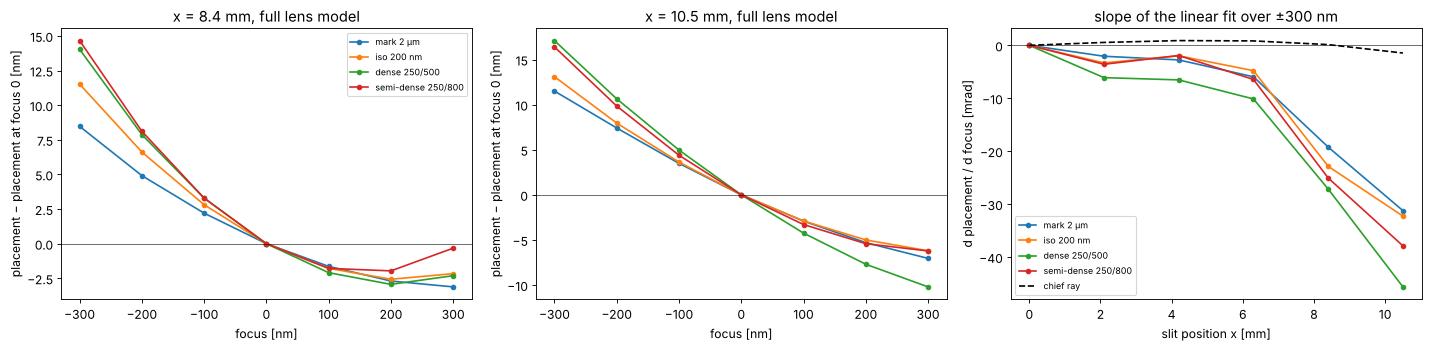

In [9]:
xs_slit = np.linspace(0, SLIT_X, 6)
curves, slit_slopes = {}, {name: [] for name in patterns}
for x in xs_slit:
    P = apodized_projector((x, 0.0), aberrations=True)
    for name, layout in patterns.items():
        pl = placement_through_focus(layout, P, (x, 0.0))
        curves[name, x] = pl
        slit_slopes[name].append(slope_of(pl))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for k, name in enumerate(patterns):
    for ax, x in zip(axes[:2], xs_slit[-2:]):
        pl = curves[name, x]
        ax.plot(FOCI, pl - pl[len(FOCI)//2], "o-", color=f"C{k}", ms=4, label=name)
    axes[2].plot(xs_slit, slit_slopes[name], "o-", color=f"C{k}", ms=4, label=name)
axes[2].plot(xs_slit, [1e3*chief_slope((x, 0.0))[0] for x in xs_slit], "k--", label="chief ray")
for ax, x in zip(axes[:2], xs_slit[-2:]):
    ax.set_xlabel("focus [nm]"); ax.set_ylabel("placement − placement at focus 0 [nm]")
    ax.set_title(f"x = {x} mm, full lens model"); ax.axhline(0, color="k", lw=0.5)
axes[0].legend(fontsize=8)
axes[2].set_xlabel("slit position x [mm]"); axes[2].set_ylabel("d placement / d focus [mrad]")
axes[2].set_title("slope of the linear fit over ±300 nm"); axes[2].axhline(0, color="k", lw=0.5)
axes[2].legend(fontsize=8)
fig.tight_layout()
for name in patterns:
    print(f"{name:20s}: slope across the slit [mrad]", np.round(slit_slopes[name], 1))
mark, dense = curves["mark 2 µm", SLIT_X], curves["dense 250/500", SLIT_X]
d = (mark - mark[3]) - (dense - dense[3])
print(f"mark to dense lines offset at x = {SLIT_X} mm, focus -100 / +100 nm: {np.interp(-100, FOCI, d):+.1f} / "
      f"{np.interp(100, FOCI, d):+.1f} nm")

- With the aberrations the slopes at the slit edge grow to −31 to −46
  mrad: the lens has about 0.1 waves of coma and astigmatism there, and
  coma together with defocus moves the image through focus as well (the
  curves are not straight).
- Across the slit the shifts stay within ±10 mrad up to about 6 mm and
  then grow steeply with the decentration of the pupil; the chief ray
  stays within 1.5 mrad everywhere.
- The patterns move differently. At the slit edge, 100 nm of defocus
  moves the mark and the dense lines apart by about 1.4 nm: an overlay
  error between the alignment and overlay marks and the device patterns
  that no measurement on the marks reveals.

## 7. Compensation by the illuminator

Scanners can tilt the illumination per slit position (the illuminator's
pupil fill is moved slightly off centre, e.g. by its field-dependent
optics). A source moved by $\delta\sigma$ tilts the zero order cone by about
$\delta\sigma\,\mathrm{NA}$. We choose $\delta\sigma$ at the slit edge so that the
**mark** does not move through focus (full lens model) and look at what
happens to the other patterns:

mark slope -31.24 mrad, 372 mrad per unit sigma (NA of the projector: 592 mrad); delta sigma = +0.0840 (in units of the projector NA)


mark 2 µm           :  -31.24 ->   -0.06 mrad
iso 200 nm          :  -32.27 ->   -7.02 mrad
dense 250/500       :  -45.65 ->  -27.01 mrad
semi-dense 250/800  :  -37.89 ->  -17.54 mrad


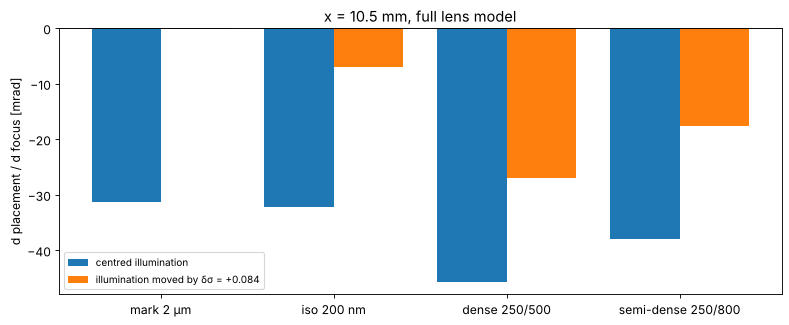

In [10]:
P_edge = apodized_projector(field, aberrations=True)


def shifted(delta):
    return Illumination(ill.s_x + delta, ill.s_y, ill.weights)


def mark_slope(delta):
    return slope_of(placement_through_focus(patterns["mark 2 µm"], P_edge, field, shifted(delta)))


s0, s1 = mark_slope(0.0), mark_slope(0.01)
delta = -0.01*s0/(s1 - s0)
print(f"mark slope {s0:+.2f} mrad, {(s1 - s0)/0.01:.0f} mrad per unit sigma "
      f"(NA of the projector: {1e3*NA_P:.0f} mrad); delta sigma = {delta:+.4f} (in units of the projector NA)")
after = {name: slope_of(placement_through_focus(layout, P_edge, field, shifted(delta)))
         for name, layout in patterns.items()}
before = {name: slit_slopes[name][-1] for name in patterns}

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(idx - 0.2, [before[n] for n in patterns], 0.4, label="centred illumination")
ax.bar(idx + 0.2, [after[n] for n in patterns], 0.4, label=f"illumination moved by δσ = {delta:+.3f}")
ax.set_xticks(idx); ax.set_xticklabels(patterns); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("d placement / d focus [mrad]"); ax.legend(fontsize=9)
ax.set_title(f"x = {X_EDGE} mm, full lens model")
fig.tight_layout()
for name in patterns:
    print(f"{name:20s}: {before[name]:+7.2f} -> {after[name]:+7.2f} mrad")

A source shifted by $\delta\sigma = 0.084$ stops the mark from moving, but
the other patterns keep 7 to 27 mrad: each pattern samples the pupil, and
its decentred rim, differently, and an illumination tilt cannot undo a
geometry error of the lens pupil for all of them. (The mark moves by 372
mrad per unit σ, less than the NA of 592 mrad that a pure tilt of the
illumination would give: its edges are not formed by the zero order alone.)
Illumination tuning suits what the illumination causes, the energetic
telecentricity of section 4; the pupil centring has to be right in the
lens (the stop position and the pupil aberrations of the design).

## Summary

- The **chief ray** of Caldwell's lens (stop on surface 30) is telecentric
  to 1.5 mrad across a 21 × 5 mm slit.
- The **energetic telecentricity** of the illumination adds up to about
  1 mrad (conventional σ 0.8 and annular 0.8/0.5) from the **coatings**
  and the **absorption**, with a sign that depends on the coating design:
  outwards for the bare lens, inwards for single layers and most for the
  LaF$_3$/MgF$_2$ V coat. The coating is part of the telecentricity budget.
- The **pupil** is decentred off axis by up to 5 % of its radius (pupil
  coma; it depends on where the stop is, which the paper does not say).
  A symmetric illumination does not see it, but every edge diffracts light
  to the rim, and the lithography simulation with the real pupil
  (`lens_apodization()`) shows pattern shifts through focus of 20–36 mrad
  at the slit edge, 30–46 mrad with the lens aberrations, different for
  each pattern.
- Scanning averages the $x$ slopes over the slit height and turns the
  $y$ slopes into image fading through focus.
- Tilting the illumination fixes one pattern (e.g. the marks) but not all
  of them: what is pattern dependent must be corrected in the lens.

Exercises: put the stop of the model on surface 31 (insert a plane surface
or move `stop_index`) and repeat sections 3 and 6; add a radial thickness
profile to the coatings (`coatings.RadialProfile`, thinner towards the rim
of steep surfaces) and see how the energetic telecentricity changes; try
a dipole illumination with `fill=` and `Illumination.dipole`.

In [11]:
print(f"run time {time.time() - t_start:.0f} s")

run time 302 s
